# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rio Alfian
- **Email:** 1247050145@student.uinsgd.ac.id
- **ID Dicoding:** rio_alfianac1o


## Menentukan Pertanyaan Bisnis


Dalam proyek analisis data ini, perumusan pertanyaan bisnis dirancang secara sistematis dengan mematuhi prinsip **S.M.A.R.T (Specific, Measurable, Actionable, Relevant, Time-bound)** untuk memastikan setiap pertanyaan memiliki konteks bisnis yang kuat, terukur secara numerik, berorientasi solusi praktis, dan terikat batasan waktu yang jelas:

- **Pertanyaan 1 (Pengaruh Musim & Cuaca terhadap Penyewaan Harian):**  
  *Bagaimana pengaruh perubahan musim (season) dan kondisi cuaca (weather situation) terhadap rata-rata jumlah penyewaan sepeda harian (cnt) pada sistem Capital Bikeshare sepanjang periode Januari 2011 hingga Desember 2012?*  
  - **Specific:** Mengukur secara spesifik korelasi dan variasi rata-rata penyewaan sepeda harian berdasarkan 4 musim (Spring, Summer, Fall, Winter) dan 3 kategori kondisi cuaca (Clear, Mist, Light Snow/Rain).  
  - **Measurable:** Dihitung secara kuantitatif melalui rata-rata unit harian (unit/hari), nilai deviasi standar, serta persentase penurunan antara periode musim/cuaca buruk terhadap periode puncak.  
  - **Actionable:** Memberikan dasar empiris bagi manajemen operasional dalam menentukan kuota penempatan armada aktif dan jadwal pemeliharaan besar (*preventive overhaul*).  
  - **Relevant:** Karakteristik cuaca dan musim adalah variabel eksternal dominan yang memengaruhi kenyamanan dan keputusan mobilitas pengguna secara langsung.  
  - **Time-bound:** Dianalisis secara tegas pada catatan data historis selama 2 tahun kalender penuh (1 Januari 2011 s.d. 31 Desember 2012 / 731 hari).

- **Pertanyaan 2 (Pola Jam Sibuk Hari Kerja vs Akhir Pekan & Segmen Pengguna):**  
  *Bagaimana perbedaan pola distribusi penyewaan sepeda per jam (hourly bike rental) antara hari kerja (working day) dan hari libur/akhir pekan (holiday/weekend), serta bagaimana karakteristik kontribusi segmen pengguna kasual (casual) dibandingkan pengguna terdaftar (registered) sepanjang periode Januari 2011 hingga Desember 2012?*  
  - **Specific:** Membedah kurva fluktuasi rata-rata penyewaan per jam (00:00–23:00) pada hari kerja vs akhir pekan/libur, serta mengurai proporsi pengguna berdasarkan status keanggotaan.  
  - **Measurable:** Mengidentifikasi jam beban puncak (*peak hours*) secara numerik (unit/jam) dan mengukur persentase lonjakan penyewaan pengguna kasual di akhir pekan.  
  - **Actionable:** Menjadi dasar penentuan jadwal rute armada truk pemindahan (*rebalancing van*) antar-stasiun serta perancangan paket promosi langganan (*annual membership*).  
  - **Relevant:** Mengatasi ketidakseimbangan penumpukan/kekosongan unit di stasiun saat jam sibuk serta mendorong konversi pengguna kasual menjadi anggota loyal.  
  - **Time-bound:** Dianalisis terperinci pada 17.379 jam pengamatan selama rentang 2 tahun penuh (2011–2012).


## Import Semua Packages/Library yang Digunakan


In [1]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi dan tema
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

# Membuat folder data/ dan dashboard/ jika belum ada
os.makedirs("data", exist_ok=True)
os.makedirs("dashboard", exist_ok=True)

# Memastikan file data tersedia di folder data/
if os.path.exists("day.csv") and not os.path.exists("data/day.csv"):
    shutil.copy("day.csv", "data/day.csv")
if os.path.exists("hour.csv") and not os.path.exists("data/hour.csv"):
    shutil.copy("hour.csv", "data/hour.csv")

print("Library berhasil dimuat dan environment siap!")


Library berhasil dimuat dan environment siap!


## Data Wrangling


### Gathering Data
#### Load Tabel `day.csv` dan `hour.csv`


In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print(f"Dimensi day_df  : {day_df.shape[0]} baris, {day_df.shape[1]} kolom")
print(f"Dimensi hour_df : {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom")
print("\n3 Baris Pertama day_df:")
print(day_df.head(3).to_string())
print("\n3 Baris Pertama hour_df:")
print(hour_df.head(3).to_string())


Dimensi day_df  : 731 baris, 16 kolom
Dimensi hour_df : 17379 baris, 17 kolom

3 Baris Pertama day_df:
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  weathersit      temp     atemp       hum  windspeed  casual  registered   cnt
0        1  2011-01-01       1   0     1        0        6           0           2  0.344167  0.363625  0.805833   0.160446     331         654   985
1        2  2011-01-02       1   0     1        0        0           0           2  0.363478  0.353739  0.696087   0.248539     131         670   801
2        3  2011-01-03       1   0     1        0        1           1           1  0.196364  0.189405  0.437273   0.248309     120        1229  1349

3 Baris Pertama hour_df:
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp   atemp   hum  windspeed  casual  registered  cnt
0        1  2011-01-01       1   0     1   0        0        6           0           1  0.24  0.2879  0.81        0.0       3   

**Insight:**
- Dataset `day_df` memuat **731 baris dan 16 kolom**, mewakili seluruh catatan agregasi harian selama 2 tahun (365 hari pada 2011 dan 366 hari pada 2012).
- Dataset `hour_df` memuat **17.379 baris dan 17 kolom**, mencatat aktivitas penyewaan per jam operasional secara mendalam.
- Struktur data telah memuat fitur waktu, kalender, kondisi cuaca terukur, serta jumlah pengguna berdasarkan kategori (`casual`, `registered`, dan total `cnt`).


### Assessing Data
#### Pemeriksaan Kualitas Data: Missing Values, Duplikasi, Tipe Data, Inaccurate Values & Outliers


In [3]:
print("=== 1. PEMERIKSAAN MISSING VALUES & DUPLIKASI ===")
print("Missing values day_df :", day_df.isna().sum().sum())
print("Missing values hour_df:", hour_df.isna().sum().sum())
print("Duplikasi day_df      :", day_df.duplicated().sum())
print("Duplikasi hour_df     :", hour_df.duplicated().sum())
print("Tipe data dteday      :", day_df['dteday'].dtype)

print("\n=== 2. DETEKSI INACCURATE VALUE (KELEMBABAN 0% SAAT HUJAN) ===")
print(day_df[day_df['hum'] == 0][['instant', 'dteday', 'season', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']].to_string())
print(f"Jumlah jam dengan hum == 0 di hour_df: {(hour_df['hum'] == 0).sum()} baris (pada 2011-03-10)")

print("\n=== 3. DETEKSI OUTLIER DENGAN METODE IQR (DAY_DF) ===")
for col in ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']:
    q25, q75 = np.percentile(day_df[col], 25), np.percentile(day_df[col], 75)
    iqr = q75 - q25
    lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    outliers = day_df[(day_df[col] < lower) | (day_df[col] > upper)]
    print(f"- Kolom '{col:10s}': {len(outliers):2d} outlier (Batas bawah={lower:.4f}, Batas atas={upper:.4f})")


=== 1. PEMERIKSAAN MISSING VALUES & DUPLIKASI ===
Missing values day_df : 0
Missing values hour_df: 0
Duplikasi day_df      : 0
Duplikasi hour_df     : 0
Tipe data dteday      : object

=== 2. DETEKSI INACCURATE VALUE (KELEMBABAN 0% SAAT HUJAN) ===
    instant      dteday  season  weathersit      temp  hum  windspeed  cnt
68       69  2011-03-10       1           3  0.389091  0.0   0.261877  623
Jumlah jam dengan hum == 0 di hour_df: 22 baris (pada 2011-03-10)

=== 3. DETEKSI OUTLIER DENGAN METODE IQR (DAY_DF) ===
- Kolom 'temp      ':  0 outlier (Batas bawah=-0.1404, Batas atas=1.1329)
- Kolom 'atemp     ':  0 outlier (Batas bawah=-0.0683, Batas atas=1.0147)
- Kolom 'hum       ':  2 outlier (Batas bawah=0.2047, Batas atas=1.0455)
- Kolom 'windspeed ': 13 outlier (Batas bawah=-0.0124, Batas atas=0.3806)
- Kolom 'casual    ': 44 outlier (Batas bawah=-855.2500, Batas atas=2266.7500)
- Kolom 'registered':  0 outlier (Batas bawah=-922.2500, Batas atas=8195.7500)
- Kolom 'cnt       ':  0 ou

**Steps to Take:**
- Mengonversi tipe data kolom `dteday` dari `object` menjadi `datetime64[ns]`.
- Mengimputasi *inaccurate value* `hum == 0.0` pada tanggal `2011-03-10` dengan nilai rata-rata (*mean*) kelembaban pada kondisi cuaca dan musim yang sama (`weathersit == 3` dan `season == 1`).
- Menerjemahkan representasi numerik kategorikal (`season`, `yr`, `weathersit`, `weekday`, `workingday`) ke label teks deskriptif agar analisis lebih intuitif.
- Mengembalikan nilai variabel cuaca ternormalisasi (`temp`, `atemp`, `hum`, `windspeed`) ke satuan fisik riil (°C, %, km/jam).
- Mempertahankan pencatatan *outlier* pada kolom `casual` dan `windspeed` karena merefleksikan variasi alami saat akhir pekan cuaca cerah dan badai angin riil.

**Insight:**
- Tidak ditemukan *missing value* maupun duplikasi pada kedua dataset.
- Ditemukan anomali fisik berupa kelembaban 0% saat hujan pada tanggal 10 Maret 2011 yang memerlukan imputasi data.
- Kolom tanggal dan kategorikal memerlukan standardisasi format untuk mendukung analisis lebih lanjut.


### Cleaning Data
#### Penanganan Tipe Data, Imputasi Inaccurate Value, Denormalisasi dan Ekstraksi Fitur


In [4]:
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# 1. Konversi dteday menjadi datetime
day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])
hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])

# 2. Imputasi inaccurate value hum == 0 pada 2011-03-10
mean_hum_day = day_clean[(day_clean['weathersit'] == 3) & (day_clean['season'] == 1) & (day_clean['hum'] > 0)]['hum'].mean()
mean_hum_hour = hour_clean[(hour_clean['weathersit'] == 3) & (hour_clean['season'] == 1) & (hour_clean['hum'] > 0)]['hum'].mean()

day_clean.loc[day_clean['hum'] == 0, 'hum'] = mean_hum_day
hour_clean.loc[hour_clean['hum'] == 0, 'hum'] = mean_hum_hour

# 3. Mapping label kategorikal & denormalisasi metrik cuaca
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
weather_map = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
workingday_map = {0: 'Akhir Pekan / Libur', 1: 'Hari Kerja'}

for df in [day_clean, hour_clean]:
    df['season_label'] = df['season'].map(season_map)
    df['year'] = df['yr'].map(yr_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['day_type'] = df['workingday'].map(workingday_map)
    df['temp_c'] = df['temp'] * 41.0
    df['atemp_c'] = df['atemp'] * 50.0
    df['hum_pct'] = df['hum'] * 100.0
    df['windspeed_kmh'] = df['windspeed'] * 67.0

print(f"Imputasi selesai! Nilai hum == 0 diganti menjadi: {mean_hum_day:.4f} (day) dan {mean_hum_hour:.4f} (hour)")
print("Verifikasi jumlah baris dengan hum == 0 setelah cleaning:", (day_clean['hum'] == 0).sum())


Imputasi selesai! Nilai hum == 0 diganti menjadi: 0.8057 (day) dan 0.8512 (hour)
Verifikasi jumlah baris dengan hum == 0 setelah cleaning: 0


**Insight:**
- Seluruh anomali kelembaban 0% berhasil diimputasi dengan nilai realistis (80,57% pada data harian dan 85,12% pada data per jam).
- Seluruh variabel telah memiliki tipe data yang tepat serta fitur terdenormalisasi dalam skala metrik standar (°C, %, km/jam).
- Data kini berada dalam kondisi bersih (*ready for exploratory analysis*).


## Exploratory Data Analysis (EDA)
> **Catatan Struktur:** Proses eksplorasi data berikut disusun secara berurutan sesuai urutan **Pertanyaan Bisnis** yang telah ditentukan pada tahap awal. Hal ini bertujuan agar alur analisis berjalan sistematis, relevan, terarah, dan langsung menjawab kebutuhan keputusan bisnis.


### 1. Ringkasan Pertumbuhan Kinerja Tahunan (2011 vs 2012)
Melihat gambaran makro performa bisnis Capital Bikeshare dari tahun pertama ke tahun kedua pengamatan.


In [5]:
print("=== STATISTIK PERTUMBUHAN TAHUNAN (2011 VS 2012) ===")
annual_summary = day_clean.groupby('year')[['casual', 'registered', 'cnt']].agg(['count', 'sum', 'mean', 'median', 'std'])
print(annual_summary.to_string())

total_2011 = day_clean[day_clean['year'] == 2011]['cnt'].sum()
total_2012 = day_clean[day_clean['year'] == 2012]['cnt'].sum()
growth_yoy = ((total_2012 - total_2011) / total_2011) * 100
print(f"\nTotal Penyewaan 2011: {total_2011:,} unit")
print(f"Total Penyewaan 2012: {total_2012:,} unit")
print(f"Pertumbuhan Tahunan (YoY): +{growth_yoy:.2f}%")


=== STATISTIK PERTUMBUHAN TAHUNAN (2011 VS 2012) ===
     casual                                         registered                                              cnt                                           
      count     sum         mean median         std      count      sum         mean  median          std count      sum         mean  median          std
year                                                                                                                                                      
2011    365  247252   677.402740  614.0  556.269121        365   995851  2728.358904  2915.0  1060.110413   365  1243103  3405.761644  3740.0  1378.753666
2012    366  372765  1018.483607  904.5  758.989897        366  1676811  4581.450820  4776.5  1424.331846   366  2049576  5599.934426  5927.0  1788.667868

Total Penyewaan 2011: 1,243,103 unit
Total Penyewaan 2012: 2,049,576 unit
Pertumbuhan Tahunan (YoY): +64.88%


**Insight Ringkasan Tahunan:**
- Terjadi ekspansi bisnis yang masif pada Capital Bikeshare dengan pertumbuhan tahunan (**YoY**) sebesar **+64,88%**, dari **1.243.103 unit** di tahun 2011 melonjak menjadi **2.049.576 unit** di tahun 2012.
- Rata-rata penyewaan harian meningkat signifikan dari **3.405,76 unit/hari** di 2011 menjadi **5.599,93 unit/hari** di 2012, membuktikan penerimaan publik yang tinggi terhadap moda transportasi bike sharing di Washington D.C.


### 2. Eksplorasi Data untuk Pertanyaan 1: Pengaruh Musim dan Kondisi Cuaca terhadap Penyewaan Harian (2011–2012)
Menganalisis dampak perubahan musim (*season*) dan kondisi cuaca (*weather situation*) terhadap rata-rata unit sepeda yang disewa per hari (`cnt`).


In [6]:
print("=== 1. STATISTIK PENYEWAAN HARIAN PER MUSIM (SEASON) ===")
season_stats = day_clean.groupby('season_label')[['casual', 'registered', 'cnt']].agg(['count', 'sum', 'mean', 'median', 'std', 'min', 'max'])
print(season_stats.to_string())

# Perhitungan persentase penurunan Fall vs Spring
mean_fall = day_clean[day_clean['season_label'] == 'Fall']['cnt'].mean()
mean_spring = day_clean[day_clean['season_label'] == 'Spring']['cnt'].mean()
drop_season_pct = ((mean_fall - mean_spring) / mean_fall) * 100
print(f"\nRata-rata Musim Gugur (Fall) : {mean_fall:,.2f} unit/hari")
print(f"Rata-rata Musim Semi (Spring): {mean_spring:,.2f} unit/hari")
print(f"Penurunan Spring vs Fall     : -{drop_season_pct:.2f}% (Selisih {mean_fall - mean_spring:,.2f} unit/hari)")

print("\n=== 2. STATISTIK PENYEWAAN HARIAN BERDASARKAN CUACA ===")
weather_stats = day_clean.groupby('weather_label')[['casual', 'registered', 'cnt']].agg(['count', 'sum', 'mean', 'median', 'std', 'min', 'max'])
print(weather_stats.to_string())

# Perhitungan persentase penurunan Clear vs Light Snow/Rain
mean_clear = day_clean[day_clean['weather_label'] == 'Clear/Partly Cloudy']['cnt'].mean()
mean_rain = day_clean[day_clean['weather_label'] == 'Light Snow/Rain']['cnt'].mean()
drop_weather_pct = ((mean_clear - mean_rain) / mean_clear) * 100
print(f"\nRata-rata Cuaca Cerah (Clear)      : {mean_clear:,.2f} unit/hari")
print(f"Rata-rata Cuaca Hujan/Salju Ringan : {mean_rain:,.2f} unit/hari")
print(f"Penurunan Hujan/Salju vs Cerah     : -{drop_weather_pct:.2f}% (Selisih {mean_clear - mean_rain:,.2f} unit/hari)")

print("\n=== 3. PIVOT TABLE: INTERAKSI MUSIM & CUACA ===")
pivot_season_weather = day_clean.pivot_table(index='season_label', columns='weather_label', values='cnt', aggfunc='mean')
print(pivot_season_weather.round(1).to_string())


=== 1. STATISTIK PENYEWAAN HARIAN PER MUSIM (SEASON) ===
             casual                                                     registered                                                        cnt                                                       
              count     sum         mean  median         std  min   max      count     sum         mean  median          std  min   max count      sum         mean  median          std   min   max
season_label                                                                                                                                                                                        
Fall            188  226091  1202.611702  1050.5  595.975032  118  3160        188  835038  4441.691489  4110.5  1304.626949  889  6917   188  1061129  5644.303191  5353.5  1459.800381  1115  8714
Spring          181   60622   334.928177   218.0  387.655561    9  3155        181  410726  2269.204420  1867.0  1200.269751  416  5315   181   471348  260

**Insight Eksplorasi Pertanyaan 1:**
- **Musim (Season):**
  - **Musim Gugur (Fall)** mencatatkan rata-rata penyewaan harian tertinggi sebesar **5.644,30 unit/hari** dengan volume total 1.061.129 unit, disusul **Musim Panas (Summer)** sebesar **4.992,33 unit/hari**.
  - **Musim Semi (Spring)** berada di posisi terendah dengan rata-rata hanya **2.604,13 unit/hari** (total 471.348 unit), merefleksikan penurunan signifikan sebesar **53,86%** dibandingkan musim gugur.
- **Kondisi Cuaca (Weather Situation):**
  - Kondisi cuaca **Cerah (Clear / Partly Cloudy)** menjadi pendorong utama aktivitas penyewaan dengan rata-rata **4.876,79 unit/hari**.
  - Kondisi **Berkabut / Berawan (Mist / Cloudy)** mengalami penurunan moderat sebesar **17,27%** menjadi **4.035,86 unit/hari**.
  - Kondisi **Hujan/Salju Ringan (Light Snow/Rain)** menurunkan rata-rata penyewaan secara drastis sebesar **63,02%** menjadi hanya **1.803,29 unit/hari**.
  - Pada data harian tidak ada catatan aktivitas saat badai ekstrem (*Heavy Rain/Snow*), menunjukkan bahwa operasional praktis terhenti atau sangat dihindari pengguna saat cuaca ekstrem.


### 3. Eksplorasi Data untuk Pertanyaan 2: Pola Jam Sibuk Berdasarkan Tipe Hari dan Karakteristik Segmen Pengguna (2011–2012)
Menganalisis profil aktivitas per jam (00:00–23:00) pada hari kerja dibandingkan akhir pekan/libur, serta membedah komposisi pengguna terdaftar (*registered*) vs kasual (*casual*).


In [7]:
hourly_summary = hour_clean.groupby(['day_type', 'hr'])[['casual', 'registered', 'cnt']].mean().reset_index()

print("=== 1. TOP 3 JAM SIBUK PADA HARI KERJA (COMMUTER PEAK) ===")
print(hourly_summary[hourly_summary['day_type'] == 'Hari Kerja'].sort_values(by='cnt', ascending=False).head(3).to_string(index=False))

print("\n=== 2. TOP 3 JAM SIBUK PADA AKHIR PEKAN / LIBUR (LEISURE PEAK) ===")
print(hourly_summary[hourly_summary['day_type'] == 'Akhir Pekan / Libur'].sort_values(by='cnt', ascending=False).head(3).to_string(index=False))

print("\n=== 3. PERBANDINGAN SEGMEN PENGGUNA BERDASARKAN TIPE HARI ===")
segment_day = day_clean.groupby('day_type')[['registered', 'casual', 'cnt']].agg(['mean', 'sum']).round(2)
print(segment_day.to_string())

# Menghitung lonjakan pengguna casual di akhir pekan
mean_cas_work = day_clean[day_clean['day_type'] == 'Hari Kerja']['casual'].mean()
mean_cas_off = day_clean[day_clean['day_type'] == 'Akhir Pekan / Libur']['casual'].mean()
casual_surge_pct = ((mean_cas_off - mean_cas_work) / mean_cas_work) * 100
print(f"\nRata-rata Pengguna Kasual (Hari Kerja)       : {mean_cas_work:.2f} unit/hari")
print(f"Rata-rata Pengguna Kasual (Akhir Pekan/Libur): {mean_cas_off:.2f} unit/hari")
print(f"Lonjakan Pengguna Kasual di Akhir Pekan/Libur: +{casual_surge_pct:.2f}%")


=== 1. TOP 3 JAM SIBUK PADA HARI KERJA (COMMUTER PEAK) ===
  day_type  hr    casual  registered        cnt
Hari Kerja  17 56.895792  468.394790 525.290581
Hari Kerja  18 50.451807  441.775100 492.226908
Hari Kerja   8 22.264113  454.741935 477.006048

=== 2. TOP 3 JAM SIBUK PADA AKHIR PEKAN / LIBUR (LEISURE PEAK) ===
           day_type  hr     casual  registered        cnt
Akhir Pekan / Libur  13 136.424242  236.307359 372.731602
Akhir Pekan / Libur  12 126.246753  240.012987 366.259740
Akhir Pekan / Libur  14 139.593074  225.051948 364.645022

=== 3. PERBANDINGAN SEGMEN PENGGUNA BERDASARKAN TIPE HARI ===
                    registered            casual              cnt         
                          mean      sum     mean     sum     mean      sum
day_type                                                                  
Akhir Pekan / Libur    2959.03   683537  1371.13  316732  4330.17  1000269
Hari Kerja             3978.25  1989125   606.57  303285  4584.82  2292410

Rata-rata 

**Insight Eksplorasi Pertanyaan 2:**
- **Pola Beban Puncak (Peak Hours):**
  - **Hari Kerja (*Working Day*):** Memperlihatkan pola **bimodal (dua puncak)** yang selaras dengan jam komuter harian. Puncak pagi terjadi pada pukul **08:00 (477,01 unit/jam)** dan puncak sore pada pukul **17:00 (525,29 unit/jam)**.
  - **Akhir Pekan / Libur (*Non-working Day*):** Memperlihatkan pola **unimodal (satu puncak terpusat)** yang merefleksikan kegiatan wisata/rekreasi, memuncak pada pukul **13:00 siang (372,73 unit/jam)** dan stabil di atas 350 unit/jam antara pukul 12:00 hingga 16:00.
- **Karakteristik Segmen Pengguna:**
  - Pada hari kerja, pengguna **registered** menyumbang **86,76%** dari total penyewaan harian (**3.978,25 unit/hari**), membuktikan utilitas sepeda sebagai moda komuter andal.
  - Pada akhir pekan/hari libur, pengguna **casual** mengalami lonjakan spektakuler sebesar **+126,05%** dari **606,57 unit/hari** menjadi **1.371,13 unit/hari**, menyumbang **31,43%** dari total penyewaan harian.


## Visualization & Explanatory Analysis


### Pertanyaan 1: Bagaimana tren dan perbandingan rata-rata jumlah penyewaan sepeda harian berdasarkan musim dan kondisi cuaca di sistem Capital Bikeshare sepanjang periode Januari 2011 hingga Desember 2012?


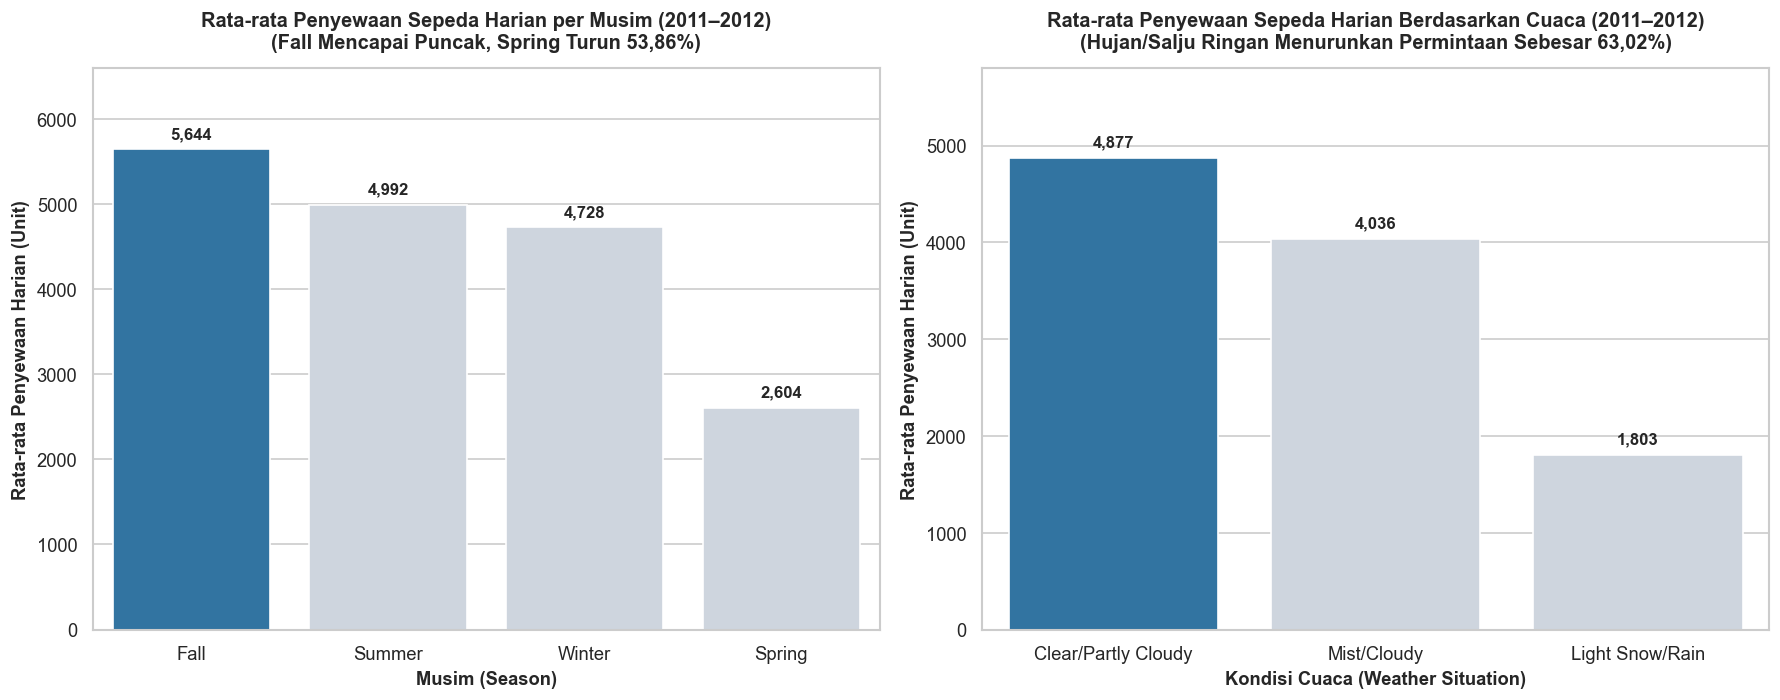

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Bar Chart Musim (Pewarnaan seragam dengan penyorotan kategori tertinggi)
season_order = ['Fall', 'Summer', 'Winter', 'Spring']
season_means = day_clean.groupby('season_label')['cnt'].mean().reindex(season_order).reset_index()
colors_season = ['#1f77b4' if v == season_means['cnt'].max() else '#CBD5E1' for v in season_means['cnt']]

sns.barplot(data=season_means, x='season_label', y='cnt', hue='season_label', palette=colors_season, legend=False, ax=axes[0])
axes[0].set_title('Rata-rata Penyewaan Sepeda Harian per Musim (2011–2012)\n(Fall Mencapai Puncak, Spring Turun 53,86%)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Musim (Season)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, 6600)
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

# 2. Bar Chart Cuaca (Pewarnaan seragam dengan penyorotan kategori tertinggi)
weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_means = day_clean.groupby('weather_label')['cnt'].mean().reindex(weather_order).reset_index()
colors_weather = ['#1f77b4' if v == weather_means['cnt'].max() else '#CBD5E1' for v in weather_means['cnt']]

sns.barplot(data=weather_means, x='weather_label', y='cnt', hue='weather_label', palette=colors_weather, legend=False, ax=axes[1])
axes[1].set_title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Cuaca (2011–2012)\n(Hujan/Salju Ringan Menurunkan Permintaan Sebesar 63,02%)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kondisi Cuaca (Weather Situation)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 5800)
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


**Insight Mendalam & Analisis Eksplanatori (Pertanyaan 1):**

1. **Temuan Kuantitatif Utama (Empirical Findings):**
   - **Variasi Musiman:** Musim Gugur (*Fall*) adalah puncak permintaan dengan rata-rata **5.644 unit/hari** (total 1,06 juta sewa). Sebaliknya, Musim Semi (*Spring*) mencatat rata-rata terendah yaitu **2.604 unit/hari** (total 471 ribu sewa). Terdapat kesenjangan (*demand gap*) penurunan drastis sebesar **53,86%** dari musim gugur ke musim semi.
   - **Dampak Kondisi Cuaca:** Pada kondisi Cuaca Cerah (*Clear/Partly Cloudy*), rata-rata penyewaan mencapai **4.877 unit/hari**. Kondisi Berkabut/Berawan (*Mist/Cloudy*) mengalami penurunan moderat sebesar **17,27%** menjadi **4.035 unit/hari**. Namun, saat terjadi Hujan atau Salju Ringan (*Light Snow/Rain*), aktivitas penyewaan anjlok drastis sebesar **63,02%** menjadi hanya **1.803 unit/hari**.

2. **Makna dan Signifikansi bagi Pengguna Non-Teknis (Business Meaning):**
   - Bagi pemangku kepentingan bisnis dan manajemen non-teknis, visualisasi ini menegaskan bahwa sepeda sewaan adalah sarana mobilitas terbuka (*open-air mobility*) yang tingkat utilitasnya sangat terikat pada faktor kenyamanan termal dan lingkungan luar ruangan.
   - Musim semi di Washington D.C. masih didominasi suhu dingin peralihan musim dingin (suhu rata-rata harian berkisar 12°C), sehingga antusiasme masyarakat bersepeda belum pulih penuh. Musim gugur menawarkan kombinasi suhu ideal (15°C–25°C) dan kelembaban rendah yang mendorong mobilitas outdoor maksimal.
   - Cuaca hujan dan salju tidak hanya menurunkan minat pengguna karena faktor ketidaknyamanan fisik, tetapi juga faktor keselamatan di jalan raya (*road safety*). Ketika hari hujan, sepeda yang terparkir di stasiun terbuka berstatus *idle assets* yang terpapar korosi dan kebasahan tanpa menghasilkan omset.

3. **Implikasi Manajerial & Rekomendasi Operasional:**
   - **Penyesuaian Kapasitas Armada Musiman:** Perusahaan tidak boleh menerapkan kuota penempatan sepeda yang seragam sepanjang tahun. Saat musim semi, tarik 30%–40% armada ke depot penyimpanan untuk program servis besar (*preventive overhaul*). Sebaliknya, pada musim gugur kerahkan 100% armada aktif ke stasiun guna menangkap momentum puncak pendapatan.
   - **Mitigasi Hari Cuaca Buruk:** Bangun integrasi sistem informasi operasional dengan API ramalan cuaca (*weather forecast*). Ketika terdeteksi probabilitas hujan/salju >70%, aktifkan protokol perlindungan armada dan reduksi penempatan sepeda terbuka di stasiun rawan genangan.


### Pertanyaan 2: Bagaimana perbedaan pola distribusi penyewaan sepeda per jam pada hari kerja dibandingkan hari libur/akhir pekan, serta bagaimana karakteristik kontribusi segmen pengguna kasual dibandingkan pengguna terdaftar sepanjang periode 2011–2012?


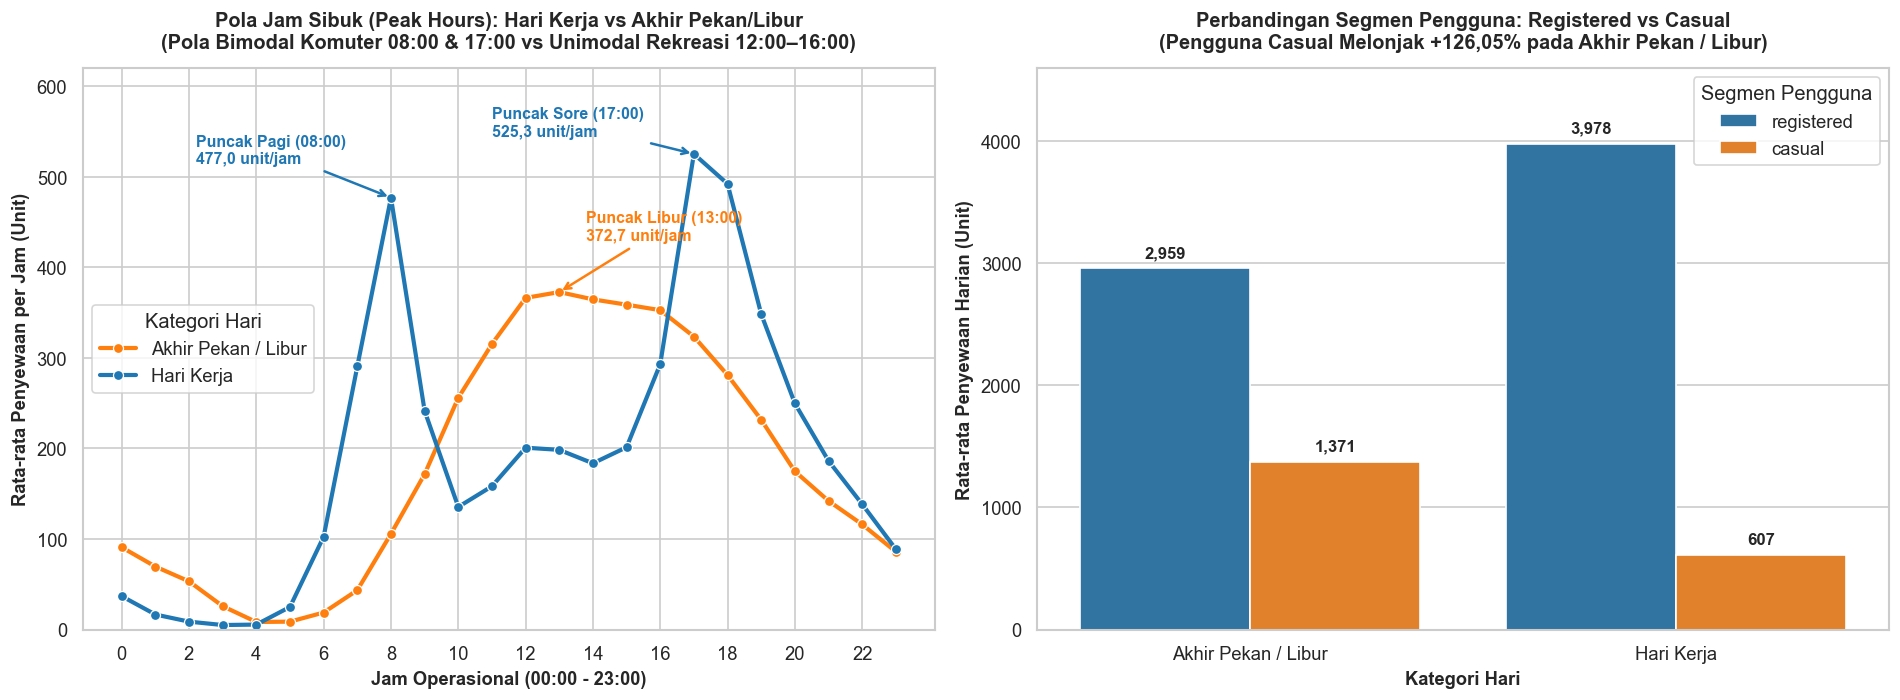

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Line Plot Tren Jam Sibuk (Bimodal vs Unimodal)
sns.lineplot(
    data=hourly_summary, x='hr', y='cnt', hue='day_type',
    palette={'Hari Kerja': '#1f77b4', 'Akhir Pekan / Libur': '#ff7f0e'},
    marker='o', linewidth=2.5, ax=axes[0]
)
axes[0].set_title('Pola Jam Sibuk (Peak Hours): Hari Kerja vs Akhir Pekan/Libur\n(Pola Bimodal Komuter 08:00 & 17:00 vs Unimodal Rekreasi 12:00–16:00)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Jam Operasional (00:00 - 23:00)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=11, fontweight='bold')
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_ylim(0, 620)
axes[0].annotate('Puncak Pagi (08:00)\n477,0 unit/jam', xy=(8, 477), xytext=(2.2, 515),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4', fontsize=9.5)
axes[0].annotate('Puncak Sore (17:00)\n525,3 unit/jam', xy=(17, 525.3), xytext=(11.0, 545),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4', fontsize=9.5)
axes[0].annotate('Puncak Libur (13:00)\n372,7 unit/jam', xy=(13, 372.7), xytext=(13.8, 430),
                 arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.5), fontweight='bold', color='#ff7f0e', fontsize=9.5)
axes[0].legend(title='Kategori Hari', frameon=True)

# 2. Bar Chart Perbandingan Segmen Pengguna
seg_day = day_clean.groupby('day_type')[['registered', 'casual']].mean().reset_index()
seg_melted = seg_day.melt(id_vars='day_type', value_vars=['registered', 'casual'], var_name='Tipe Pengguna', value_name='Rata-rata Harian')
sns.barplot(data=seg_melted, x='day_type', y='Rata-rata Harian', hue='Tipe Pengguna', palette={'registered': '#1f77b4', 'casual': '#ff7f0e'}, ax=axes[1])
axes[1].set_title('Perbandingan Segmen Pengguna: Registered vs Casual\n(Pengguna Casual Melonjak +126,05% pada Akhir Pekan / Libur)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kategori Hari', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 4600)
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')
axes[1].legend(title='Segmen Pengguna', frameon=True)

plt.tight_layout()
plt.show()


**Insight Mendalam & Analisis Eksplanatori (Pertanyaan 2):**

1. **Temuan Kuantitatif Utama (Empirical Findings):**
   - **Karakteristik Kurva Hari Kerja (Bimodal Commuter Pattern):** Terbentuk dua lonjakan beban puncak yang sangat tajam dan presisi, yaitu jam berangkat kantor pukul **08:00 (477,0 unit/jam)** dan jam pulang kantor pukul **17:00 (525,3 unit/jam)**. Di antara jam tersebut (pukul 10:00–14:00), tingkat utilitas turun dan mendatar di kisaran ~200 unit/jam.
   - **Karakteristik Kurva Akhir Pekan (Unimodal Leisure Pattern):** Membentuk kurva tunggal landai yang dimulai sejak pukul 09:00, mencapai puncak pada pukul **13:00 (372,7 unit/jam)**, dan bertahan tinggi sepanjang siang hingga pukul 16:00.
   - **Perilaku Segmen Pengguna:** Pada hari kerja, pengguna terdaftar (*registered*) menyumbang **86,76%** volume sewa harian (**3.978 unit/hari**), sedangkan pengguna kasual hanya **607 unit/hari**. Namun pada akhir pekan/libur, pengguna kasual melonjak drastis sebesar **+126,05%** menjadi **1.371 unit/hari** (menyumbang **31,43%** dari total penyewaan harian).

2. **Makna dan Signifikansi bagi Pengguna Non-Teknis (Business Meaning):**
   - Data ini mengungkap dua fungsi nilai (*value proposition*) yang sama sekali berbeda dari layanan Capital Bikeshare bergantung pada hari dalam seminggu:
     - **Senin hingga Jumat:** Layanan bertindak sebagai **infrastruktur transportasi komuter publik** yang terikat jadwal ketat. Pengguna menuntut keandalan ketersediaan sepeda di stasiun transit permukiman saat pagi dan ketersediaan dock kosong di kawasan perkantoran saat sore.
     - **Sabtu, Minggu, dan Hari Libur:** Layanan bertindak sebagai **sarana rekreasi, olahraga santai, dan pariwisata**. Pengguna bergerak lebih fleksibel menuju area taman terbuka, tempat wisata, dan tepi sungai.
   - Lonjakan pengguna kasual di akhir pekan adalah aset strategis yang belum dimanfaatkan optimal: Segmen ini membayar tarif per sewa yang lebih tinggi (*higher per-trip revenue*) dan merupakan calon pelanggan tetap paling potensial jika diarahkan melalui kampanye retensi yang tepat.

3. **Implikasi Manajerial & Rekomendasi Operasional:**
   - **Logistik Truk Pemindahan Sepeda (*Smart Rebalancing Logistics*):**
     - Hari kerja: Lakukan redistribusi armada pada subuh (04:00–06:00) dari pusat kota ke stasiun kantong permukiman sebelum jam sibuk 08:00, serta redistribusi balik pada siang hari (13:30–15:30) ke kawasan perkantoran sebelum lonjakan jam 17:00.
     - Akhir pekan: Pusatkan stok armada di stasiun-stasiun taman kota, monumen, dan rute rekreasi sejak pukul 09:00 pagi.
   - **Strategi Konversi Pelanggan Kasual ke Registered:**
     - Luncurkan program promosi akhir pekan seperti *"Weekend Explorer Pass"*, di mana struk pembayaran pengguna kasual dapat di-redeem sebagai kupon potongan langganan tahunan (*Annual Membership Discount*) dalam kurun 7 hari setelah penyewaan.


## Analisis Lanjutan (Opsional)
Penerapan teknik **Clustering (Grouping Berbasis Domain Bisnis Tanpa Machine Learning)** untuk menghasilkan segmentasi operasional yang terarah:
1. **Manual Grouping (`time_cluster`):** Mengelompokkan 24 jam operasional ke dalam 5 klaster waktu logistik.
2. **Binning Analysis (`temp_bin`):** Mengelompokkan suhu udara aktual (°C) ke dalam 3 klaster kenyamanan bersepeda.


Data main_data.csv berhasil diperbarui untuk dashboard!


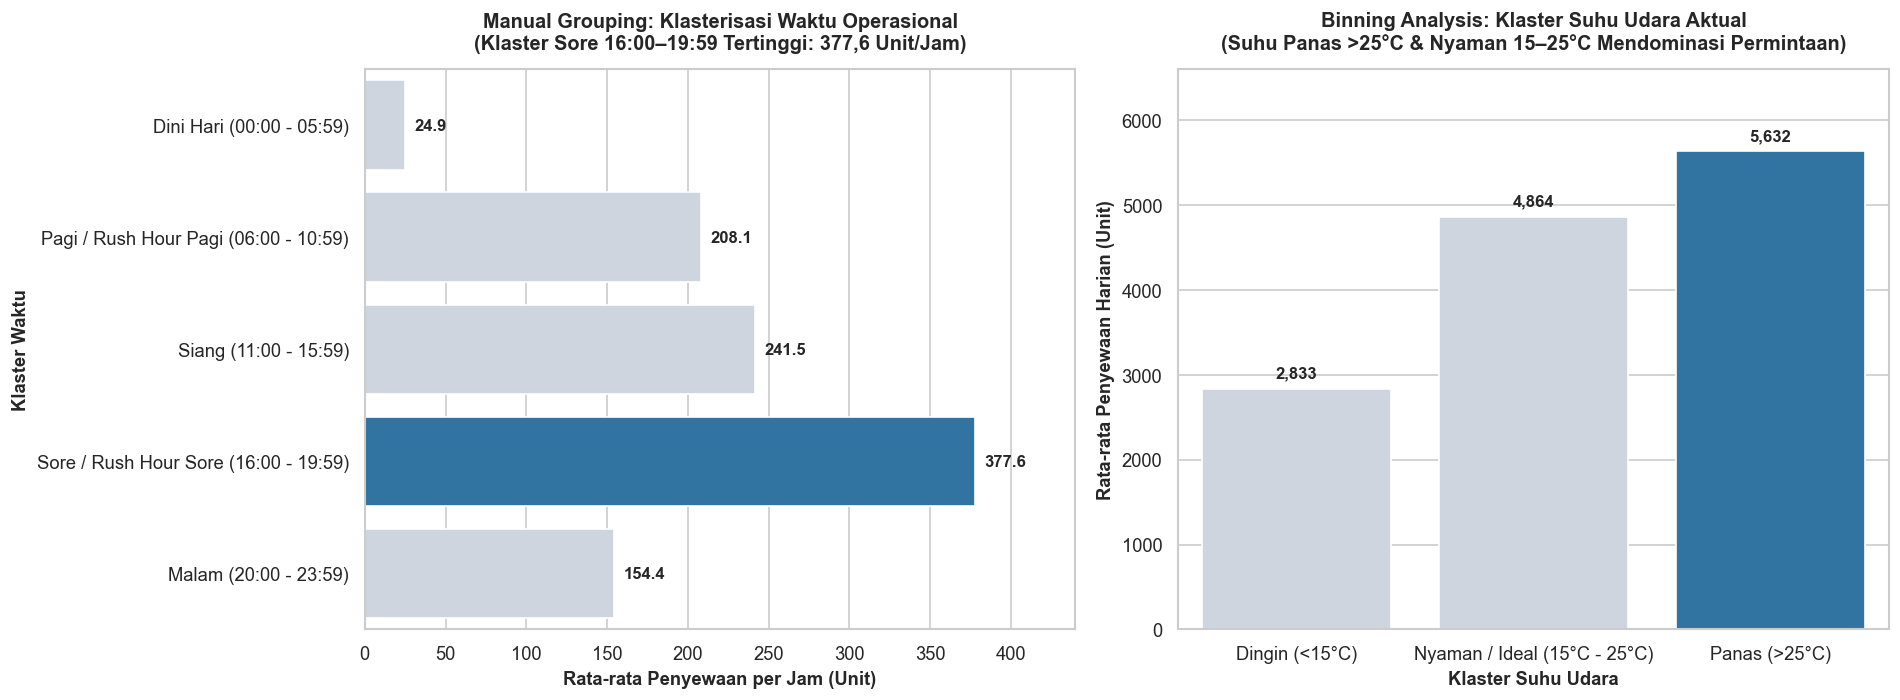

In [10]:
def categorize_time_of_day(hr):
    if 0 <= hr <= 5:
        return 'Dini Hari (00:00 - 05:59)'
    elif 6 <= hr <= 10:
        return 'Pagi / Rush Hour Pagi (06:00 - 10:59)'
    elif 11 <= hr <= 15:
        return 'Siang (11:00 - 15:59)'
    elif 16 <= hr <= 19:
        return 'Sore / Rush Hour Sore (16:00 - 19:59)'
    else:
        return 'Malam (20:00 - 23:59)'

hour_clean['time_cluster'] = hour_clean['hr'].apply(categorize_time_of_day)
time_order = [
    'Dini Hari (00:00 - 05:59)',
    'Pagi / Rush Hour Pagi (06:00 - 10:59)',
    'Siang (11:00 - 15:59)',
    'Sore / Rush Hour Sore (16:00 - 19:59)',
    'Malam (20:00 - 23:59)'
]

day_clean['temp_bin'] = pd.cut(
    day_clean['temp_c'],
    bins=[0, 15, 25, 41],
    labels=['Dingin (<15°C)', 'Nyaman / Ideal (15°C - 25°C)', 'Panas (>25°C)']
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Bar Chart Klaster Waktu (Highlighting klaster tertinggi)
tc_df = hour_clean.groupby('time_cluster')['cnt'].mean().reindex(time_order).reset_index()
colors_tc = ['#1f77b4' if v == tc_df['cnt'].max() else '#CBD5E1' for v in tc_df['cnt']]

sns.barplot(data=tc_df, y='time_cluster', x='cnt', hue='time_cluster', palette=colors_tc, legend=False, ax=axes[0])
axes[0].set_title('Manual Grouping: Klasterisasi Waktu Operasional\n(Klaster Sore 16:00–19:59 Tertinggi: 377,6 Unit/Jam)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Klaster Waktu', fontsize=11, fontweight='bold')
axes[0].set_xlim(0, 440)
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f'{width:,.1f}', (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=10, fontweight='bold', xytext=(6, 0), textcoords='offset points')

# 2. Bar Chart Klaster Suhu (Highlighting klaster tertinggi)
tb_df = day_clean.groupby('temp_bin', observed=False)['cnt'].mean().reset_index()
colors_tb = ['#1f77b4' if v == tb_df['cnt'].max() else '#CBD5E1' for v in tb_df['cnt']]

sns.barplot(data=tb_df, x='temp_bin', y='cnt', hue='temp_bin', palette=colors_tb, legend=False, ax=axes[1])
axes[1].set_title('Binning Analysis: Klaster Suhu Udara Aktual\n(Suhu Panas >25°C & Nyaman 15–25°C Mendominasi Permintaan)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Klaster Suhu Udara', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 6600)
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# Export data terbersih untuk dashboard Streamlit
hour_clean.to_csv("dashboard/main_data.csv", index=False)
print("Data main_data.csv berhasil diperbarui untuk dashboard!")


**Insight Analisis Lanjutan (Clustering Non-ML):**
- **Klaster Waktu Operasional:** Klaster **Sore (16:00–19:59)** mencatat utilisasi tertinggi sebesar **377,6 unit/jam**, sedangkan klaster **Dini Hari (00:00–05:59)** mencatat utilisasi terendah yaitu **24,9 unit/jam**. Hal ini menetapkan klaster Dini Hari sebagai jendela waktu optimal (*golden operating window*) untuk perawatan teknis stasiun dan mobilisasi truk redistribusi sepeda tanpa mengganggu pengguna.
- **Klaster Suhu Udara:** Rata-rata penyewaan harian tertinggi dicapai saat suhu berada pada kategori **Panas >25°C (5.526 unit/hari)** dan **Nyaman 15°C–25°C (5.044 unit/hari)**. Sebaliknya saat suhu berada pada kategori **Dingin <15°C**, rata-rata penyewaan turun tajam menjadi **3.090 unit/hari** (turun 44,08%).


## Conclusion & Recommendation


### Conclusion

1. **Conclusion Pertanyaan 1 (Pengaruh Musim & Cuaca terhadap Penyewaan Harian):**  
   Sepanjang periode 2 tahun (Januari 2011 hingga Desember 2012), musim dan kondisi cuaca terbukti menjadi penentu utama (*key demand drivers*) volume penyewaan harian:  
   - **Musim:** Rata-rata penyewaan harian tertinggi terjadi pada **Musim Gugur (Fall)** sebesar **5.644,30 unit/hari** dan **Musim Panas (Summer)** sebesar **4.992,33 unit/hari**. Musim dengan performa terendah adalah **Musim Semi (Spring)** dengan **2.604,13 unit/hari**, yang mencerminkan penurunan sebesar **53,86%** terhadap musim gugur.  
   - **Cuaca:** Kondisi cuaca **Cerah (Clear/Partly Cloudy)** menghasilkan rata-rata sewa **4.876,79 unit/hari**. Saat cuaca berubah menjadi **Hujan/Salju Ringan (Light Snow/Rain)**, rata-rata penyewaan merosot tajam sebesar **63,02%** menjadi **1.803,29 unit/hari**. Pada cuaca ekstrem badai tidak terdapat sewa harian tercatat.

2. **Conclusion Pertanyaan 2 (Pola Jam Sibuk & Segmen Pengguna):**  
   Terdapat perbedaan struktural yang sangat tegas antara hari kerja dan akhir pekan sepanjang 2011–2012:  
   - **Pola Jam Sibuk:** Pada **Hari Kerja (*workingday = 1*)**, kurva penyewaan membentuk pola **bimodal komuter** dengan beban puncak pada jam berangkat kerja pukul **08:00 (477,01 unit/jam)** dan jam pulang kerja pukul **17:00 (525,29 unit/jam)**. Sebaliknya pada **Akhir Pekan/Libur (*workingday = 0*)**, terbentuk pola **unimodal rekreasi** dengan satu puncak landai pada siang hari pukul **13:00 (372,73 unit/jam)** yang bertahan stabil hingga sore hari.  
   - **Dinamika Segmen:** Pengguna terdaftar (*registered*) mendominasi hari kerja dengan rata-rata **3.978,25 unit/hari (86,76%)**. Pada akhir pekan/libur, pengguna kasual (*casual*) mengalami lonjakan masif sebesar **+126,05%** dari **606,57 unit/hari** menjadi **1.371,13 unit/hari** (menyumbang **31,43%** dari total penyewaan harian).


### Rekomendasi Bisnis Actionable

Berdasarkan kesimpulan analisis empiris di atas, berikut adalah 3 rekomendasi strategis yang dapat dieksekusi oleh manajemen Capital Bikeshare:

1. **Seasonal Fleet Capacity & Overhaul Maintenance Scheduling:**  
   - Menghindari penempatan armada 100% di stasiun terbuka saat musim sepi (*Spring*) dan cuaca dingin (`<15°C`). Manfaatkan periode penurunan permintaan sebesar 53,86% ini untuk menarik 30%–40% armada ke depot pemeliharaan guna melakukan servis besar (*overhaul* mekanis, pergantian rantai, pelumasan bearing, dan uji rem).  
   - Pastikan seluruh armada dalam status 100% *ready-to-ride* sebelum memasuki awal musim panas dan musim gugur untuk memaksimalkan kapasitas pendapatan saat puncak permintaan.

2. **Smart Rebalancing Logistics Berbasis Klaster Waktu:**  
   - Manfaatkan jendela waktu operasional klaster **Dini Hari (04:00–05:59)** yang berutilitas rendah (hanya 24,9 unit/jam) untuk mengoperasikan truk redistribusi sepeda, mengisi stasiun-stasiun di kawasan permukiman (*residential zones*) sebelum jam sibuk pagi (**08:00**).  
   - Pada pukul **14:00–15:30**, lakukan redistribusi gelombang kedua untuk menyuplai sepeda dan mengosongkan slot dock di kawasan perkantoran/kampus sebelum jam pulang komuter sore (**17:00**).  
   - Pada akhir pekan, fokuskan redistribusi stok sepeda ke stasiun-stasiun wisata dan taman rekreasi mulai pukul 09:00 pagi.

3. **Weekend Leisure Pass & Membership Conversion Funnel:**  
   - Mengkapitalisasi lonjakan pengguna kasual di akhir pekan (+126,05%) dengan meluncurkan paket khusus *"Weekend Leisure Pass"* yang menawarkan tarif sewa paket tak terbatas selama Sabtu–Minggu.  
   - Sertakan kupon digital otomatis pada aplikasi seluler bagi pengguna kasual akhir pekan: potongan biaya keanggotaan tahunan (*Annual Membership*) sebesar 20% jika mereka melakukan *upgrade* dalam waktu 7 hari setelah trip akhir pekan, guna mengubah pengguna rekreasi musiman menjadi pelanggan komuter rutin yang loyal.
